# Validated GenAI Analysis of Public Comments on the FTC's Personalized-Pricing Policy

## 1. Business understanding

**Context.** In August 2026 the Federal Trade Commission (FTC) proposed an enforcement policy on *personalized pricing*: businesses using a consumer's personal data to estimate what that person will pay, and setting their price accordingly. The proposal does not ban the practice. It says businesses may break the law if they fail to clearly disclose that a price is personalized, why, and what data was used. The public comment period (docket FTC-2026-1057) closed on September 25, 2026, with 3,706 public comments.

**The business problem.** Regulators, law firms and public-affairs teams must read and summarize thousands of comments like these by hand. GenAI could do this faster and more cheaply, but a misread comment misrepresents the public record. Before anyone relies on it, the AI's accuracy has to be measured against careful human judgment.

**Research questions.**

*Workflow (for organizations adopting GenAI):*
1. How accurately does an LLM classify comments compared with human coders?
2. What does it cost per comment compared with human analysts?
3. Where does it fail?
4. What controls make it safe to use?

*Findings (for companies that use personalized pricing):*

5. What do individual commenters object to: the price difference, the use of their data, or the lack of disclosure?
6. What do they want the FTC to do?

**Scope.** This study analyzes comments from **individuals**. Submissions from organizations (companies, trade groups, advocacy groups) are mostly long attached documents that need a different method; comparing them with individuals is left for future work.

**Approach.** Understand → Use → Evaluate → Govern. Findings are reported only for labels the AI has been shown to classify reliably.

## Setup

In [21]:
# Loads the libraries and defines the settings and file paths
# used in the rest of the notebook. Every setting that affects
# results is defined here, so it only needs changing in one place.

# Standard library
import os                      # environment variables (e.g., the API key)
import re                      # regular expressions, for cleaning text
import html                    # decodes HTML codes such as &rsquo; into normal characters
import json                    # reads and writes the LLM's structured (JSON) output
from pathlib import Path       # builds file paths that work on Windows and Mac

# Data analysis and plotting
import numpy as np             # numerical operations
import pandas as pd            # loading and manipulating the comment data
import matplotlib.pyplot as plt  # charts
import seaborn as sns          # nicer charts

# Machine learning and text analysis
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from sklearn.decomposition import NMF

# Reproducibility settings
# The same random seed was used to draw the comment sample from the API,
# so anyone rerunning the notebook gets exactly the same results.
SEED = 20261027

# Total public comments on docket FTC-2026-1057, as reported by the
# Regulations.gov API. Used to describe how much of the docket we analyze.
DOCKET_TOTAL = 3706

# File paths
# The notebook lives in Notebooks/, but the data is at the top of the repo.
# Find the repo's top folder by walking up until we find the Data folder,
# so the paths work no matter where the notebook is run from.
ROOT = Path.cwd()
while not (ROOT / "Data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# Input: individual comments pulled from the Regulations.gov API.
DATA_FILE = ROOT / "Data" / "individuals_sentiment_data.csv"

# Output: folder for saved charts, at the top of the repo; created if needed.
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

# Display settings
# Show up to 120 characters of each comment when printing tables.
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

# Check the input file exists before going further
# Stops the notebook with a clear message if the file is missing or misnamed,
# instead of failing later with a confusing error.
assert DATA_FILE.exists(), f"Missing {DATA_FILE}: check the folder and file name"
print("Setup complete. Data file found:", DATA_FILE)

Setup complete. Data file found: c:\Users\ADMIN\Documents\Daniels College of Business\Fall 2026\Analytics & AI\ftc-pricing-comments-genai\Data\individuals_sentiment_data.csv


## 2. Data understanding

**Source.** Public comments on docket FTC-2026-1057, retrieved from the official Regulations.gov v4 API. All comment IDs on the docket were shuffled with a fixed seed (20261027) and fetched in that order, so the comments retrieved form a simple random sample of the docket.

**Unit of observation.** One public comment submitted by an individual.

**Privacy.** Commenters' names were excluded at download. Only the comment text, posting date and, where given, the U.S. state are kept.

In [16]:
# LOAD THE DATA AND TAKE A FIRST LOOK
# Before cleaning anything, check what the file contains:
# its size, its columns, their types and any missing values.

# Load the comments
df_raw = pd.read_csv(DATA_FILE)

# Size of the dataset
# Each row should be one comment.
print(f"Rows (comments): {len(df_raw):,}")
print(f"Columns: {df_raw.shape[1]}")
print(f"Share of the full docket: {len(df_raw) / DOCKET_TOTAL:.1%} of {DOCKET_TOTAL:,} comments\n")

#  Columns and their data types
# Confirms each column was read as expected (text, numbers, dates).
print("Columns and types:")
print(df_raw.dtypes, "\n")

# Missing values per column
# Some missing values are expected (e.g., not every commenter gives a state).
print("Missing values per column:")
print(df_raw.isna().sum(), "\n")

# A few example rows
# Shows what the raw comment text looks like before cleaning.
df_raw.head()

Rows (comments): 1,566
Columns: 10
Share of the full docket: 42.3% of 3,706 comments

Columns and types:
comment_id           str
stratum              str
posted_date          str
organization     float64
state                str
withdrawn           bool
n_attachments      int64
comment_text         str
n_words            int64
shuffle_rank       int64
dtype: object 

Missing values per column:
comment_id          0
stratum             0
posted_date         0
organization     1566
state             554
withdrawn           0
n_attachments       0
comment_text        0
n_words             0
shuffle_rank        0
dtype: int64 



,comment_id,stratum,posted_date,organization,state,withdrawn,n_attachments,comment_text,n_words,shuffle_rank
0,FTC-2026-1057-0118,A_individual,2026-08-31T04:00:00Z,NaN,MA,False,0,"Dear Sir or Madam,\r\n\r\nSurveillance pricing is a threat to consumers, and the practice must be stopped altogether...",112,0
1,FTC-2026-1057-2221,A_individual,2026-09-24T04:00:00Z,NaN,FL,False,0,"Company personal pricing should not be allowed using AI, financial data, web-based information, or other individual ...",17,1
2,FTC-2026-1057-2723,A_individual,2026-09-24T04:00:00Z,NaN,NaN,False,0,Absolutely preposterous idea to set prices based on personal information!!,10,2
3,FTC-2026-1057-1366,A_individual,2026-09-23T04:00:00Z,NaN,NaN,False,0,Personalized pricing is just unfair. It pits the rich vs the middle class vs the poor. Demand that companies abandon...,22,3
4,FTC-2026-1057-3459,A_individual,2026-09-25T04:00:00Z,NaN,NaN,False,0,Life is difficult enough to have to worry about whether your shopping habits are costing you money! This is delibera...,46,4


### what the data contains

- **1,566 individual comments**, 42.3% of the 3,706 comments on the docket. They come from the first 1,630 comments in the fixed random order (the other 64 were organizations, excluded from this study), so they form a random sample of individual commenters.
- **10 columns**: a comment ID, the comment text, a word count, the posting date, the commenter's U.S. state, the position in the random order (`shuffle_rank`), and four columns describing the submission type (`stratum`, `organization`, `withdrawn`, `n_attachments`).
- **Missing values are expected, not errors.** `organization` is empty for every row because these are individuals. `state` is missing for 554 comments (35%) because giving a state is optional on Regulations.gov.
- **No missing comment text, IDs or dates**, so every row can be analyzed.
- The four submission-type columns should be the same for every row (individual, no organization, not withdrawn, no attachments). We verify this in cleaning and then drop them.

## 3. Data cleaning

Each cleaning step is checked with an `assert`, so the notebook stops with a clear message if the data is not what we expect.

In [17]:
# Turns the raw file into an analysis-ready table and checks
# every assumption we rely on later.

df = df_raw.copy()   # keep the raw data untouched for reference

# 1. Confirm every row is an individual comment
# These columns describe submission type. For individuals they should
# be identical on every row; if so, they carry no information.
assert (df["stratum"] == "A_individual").all(), "Non-individual rows found"
assert df["organization"].isna().all(), "Some rows name an organization"
assert (~df["withdrawn"]).all(), "Some comments were withdrawn"
assert (df["n_attachments"] == 0).all(), "Some comments have attachments"
df = df.drop(columns=["stratum", "organization", "withdrawn", "n_attachments"])

# 2. Clean the comment text
# Regulations.gov stores comments as HTML. Turn line-break tags into
# real line breaks, remove any other tags, decode codes like &rsquo;
# into normal characters, and collapse repeated spaces.
def clean_text(t):
    t = str(t).replace("\r\n", "\n").replace("\r", "\n")   # normalize Windows line breaks
    t = re.sub(r"(?i)<br\s*/?>", "\n", t)
    t = re.sub(r"<[^>]+>", " ", t)
    t = html.unescape(t)
    t = re.sub(r"\n{3,}", "\n\n", t)                          # at most one blank line in a row
    return re.sub(r"[ \t]+", " ", t).strip()

df["text"] = df["comment_text"].map(clean_text)
df = df.drop(columns=["comment_text"])

# 3. Recount words on the cleaned text
df["n_words"] = df["text"].str.split().str.len()

# 4. Convert the posting date from text to a real date
df["posted_date"] = pd.to_datetime(df["posted_date"]).dt.date

# 5. Flag (do not delete) very short comments
# Comments under 5 words often carry little meaning ("Stop this.").
# We keep them but flag them, so later steps can report their effect.
df["is_short"] = df["n_words"] < 5

# 6. Checks on the cleaned data
assert df["comment_id"].is_unique, "Duplicate comment IDs"
assert df["comment_id"].str.match(r"^FTC-2026-1057-\d{4}$").all(), "Unexpected ID format"
assert (df["text"].str.len() > 0).all(), "Empty comment text after cleaning"
assert not df["text"].str.contains(r"&[a-z]+;|<br", regex=True).any(), "HTML left in text"
assert not any(c in df.columns for c in ["first_name", "last_name", "firstName", "lastName"]), \
    "Personal names present (privacy rule)"

# 7. Sampling check
# Comments were fetched in a fixed random order (seed 20261027), and
# shuffle_rank records each comment's position in that order. Each
# position should appear once and fall within the docket's range.
assert df["shuffle_rank"].is_unique, "Two comments share a position in the random order"
assert df["shuffle_rank"].between(0, DOCKET_TOTAL - 1).all(), "Position outside the docket's range"

print(f"Clean dataset: {len(df):,} comments, columns: {list(df.columns)}")
print(f"Very short comments (<5 words): {df['is_short'].sum()} ({df['is_short'].mean():.1%})")
df.head()

Clean dataset: 1,566 comments, columns: ['comment_id', 'posted_date', 'state', 'n_words', 'shuffle_rank', 'text', 'is_short']
Very short comments (<5 words): 56 (3.6%)


,comment_id,posted_date,state,n_words,shuffle_rank,text,is_short
0,FTC-2026-1057-0118,2026-08-31,MA,112,0,"Dear Sir or Madam,\n\nSurveillance pricing is a threat to consumers, and the practice must be stopped altogether. It...",False
1,FTC-2026-1057-2221,2026-09-24,FL,17,1,"Company personal pricing should not be allowed using AI, financial data, web-based information, or other individual ...",False
2,FTC-2026-1057-2723,2026-09-24,NaN,10,2,Absolutely preposterous idea to set prices based on personal information!!,False
3,FTC-2026-1057-1366,2026-09-23,NaN,22,3,Personalized pricing is just unfair. It pits the rich vs the middle class vs the poor. Demand that companies abandon...,False
4,FTC-2026-1057-3459,2026-09-25,NaN,46,4,Life is difficult enough to have to worry about whether your shopping habits are costing you money! This is delibera...,False


## 4. Summary statistics

Words per comment:
count    1566.0
mean       56.5
std        91.1
min         1.0
25%        14.0
50%        28.0
75%        59.0
90%       119.0
max       820.0 

Posted between 2026-08-19 and 2026-09-28
Busiest days: 2026-09-24 (463), 2026-09-23 (378), 2026-08-31 (349)
Share posted on the 3 busiest days: 76%

State given: 65% of comments


Top 5 states: {'CA': 143, 'NY': 63, 'FL': 61, 'TX': 56, 'WA': 52}


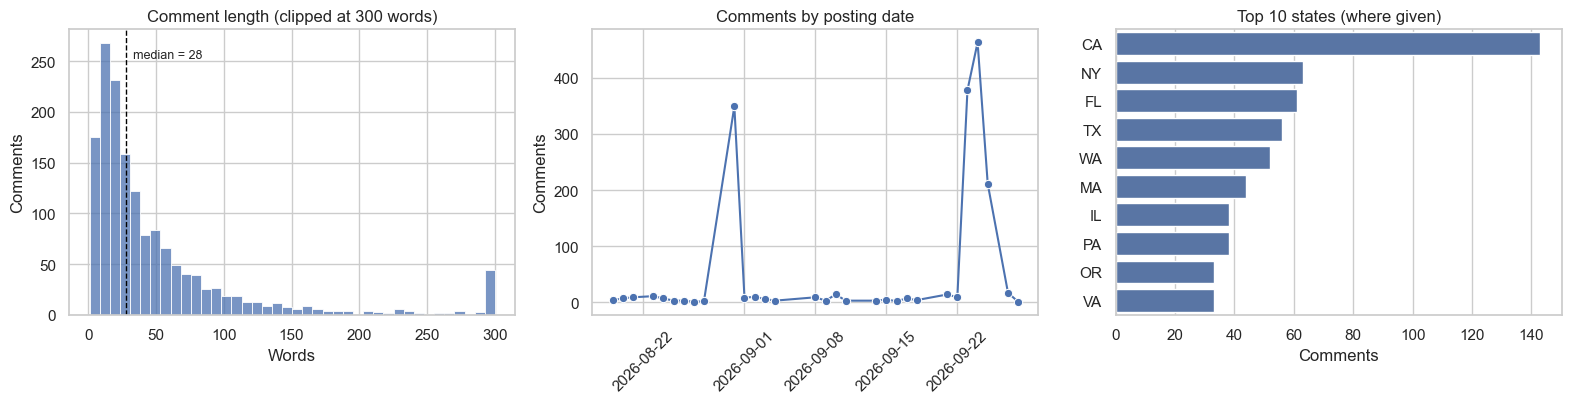

In [18]:
# SUMMARY STATISTICS
# Describes the cleaned comments: how long they are, when they
# were posted and where commenters are from.

# Comment length
# Mean and median words, plus spread. A mean far above the median
# signals a few very long comments pulling the average up.
length = df["n_words"].describe(percentiles=[.25, .5, .75, .9]).round(1)
print("Words per comment:")
print(length.to_string(), "\n")

# Posting dates
print(f"Posted between {df['posted_date'].min()} and {df['posted_date'].max()}")
by_date = df.groupby("posted_date").size()
top3 = by_date.nlargest(3)
print(f"Busiest days: " + ", ".join(f"{d} ({n})" for d, n in top3.items()))
print(f"Share posted on the 3 busiest days: {top3.sum() / len(df):.0%}\n")

# Commenter location (optional field)
print(f"State given: {df['state'].notna().mean():.0%} of comments")
print("Top 5 states:", df["state"].value_counts().head(5).to_dict())

# Charts
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))

# 1. Length distribution. Clipped at 300 words so the long tail of
#    a few very long comments does not squash the main shape.
sns.histplot(df["n_words"].clip(upper=300), bins=40, ax=axes[0], color="#4C72B0")
axes[0].axvline(df["n_words"].median(), color="black", ls="--", lw=1)
axes[0].set(title="Comment length (clipped at 300 words)", xlabel="Words", ylabel="Comments")
axes[0].text(df["n_words"].median() + 5, axes[0].get_ylim()[1] * 0.9,
             f"median = {df['n_words'].median():.0f}", fontsize=9)

# 2. Comments per posting date
sns.lineplot(x=pd.to_datetime(by_date.index), y=by_date.values, marker="o", ax=axes[1], color="#4C72B0")
axes[1].set(title="Comments by posting date", xlabel="", ylabel="Comments")
axes[1].tick_params(axis="x", rotation=45)

# 3. Top 10 states
top_states = df["state"].value_counts().head(10)
sns.barplot(x=top_states.values, y=top_states.index, ax=axes[2], color="#4C72B0")
axes[2].set(title="Top 10 states (where given)", xlabel="Comments", ylabel="")

plt.tight_layout()
plt.savefig(FIG / "summary_statistics.png", dpi=150, bbox_inches="tight")
plt.show()

### What the summary statistics show

- **Comments are short and review-like.** The median comment is 28 words; half are between 14 and 59 words, and 90% are under 120 words. A small number of long comments (up to 820 words) pull the mean up to 56.5 words, so the median is the better summary. The bar at 300 in the chart gathers all comments over 300 words.
- **Short comments suit the classification task.** Most comments state one position in a few sentences, which should make them easier to label consistently, for humans and for the LLM. The 56 comments under 5 words (3.6%) are flagged in case they carry too little information.
- **Posting is concentrated on three days.** Comments were posted between August 19 (the day the proposal was published) and September 28. 76% were posted on just three days: September 24 (463), September 23 (378) and August 31 (349). `posted_date` records when the FTC published a comment online, not when it was submitted, so these spikes most likely reflect batch posting by the agency; organized campaigns may also contribute, which we check with near-duplicate detection next.
- **Commenters come from across the country.** 65% give a U.S. state. California leads (143), followed by New York (63), Florida (61), Texas (56) and Washington (52), broadly in line with state populations.
- **Commenters are self-selected.** People choose whether to comment, so these results describe *commenters*, not the U.S. public. All findings are worded accordingly.

### 5. Form letters (near-duplicate comments)

In [20]:
# NEAR-DUPLICATE (FORM-LETTER) DETECTION
# Organized campaigns can submit many near-identical comments,
# which would inflate one position in the results. We flag them
# (not delete them) and later report findings with and without them.

DUP_THRESHOLD = 0.80   # two comments this similar or more count as near-duplicates

# 1. Turn each comment into a word-weight vector (TF-IDF) ---
# Common English words are ignored; word pairs (bigrams) capture phrasing.
X = TfidfVectorizer(stop_words="english", ngram_range=(1, 2)).fit_transform(df["text"])

# 2. Compare every comment with every other (cosine similarity, 0 to 1) ---
sim = cosine_similarity(X)
np.fill_diagonal(sim, 0)          # ignore each comment's similarity to itself

#  3. Group comments linked by high similarity
# If A ~ B and B ~ C, all three join one group (one "form letter").
_, groups = connected_components(csr_matrix(sim >= DUP_THRESHOLD), directed=False)
df["dup_group"] = groups
df["dup_group_size"] = df.groupby("dup_group")["comment_id"].transform("size")
df["is_near_duplicate"] = df["dup_group_size"] > 1

# Keep one comment per group as its representative, for the sensitivity check later.
df["is_group_representative"] = ~df.duplicated("dup_group")

# 4. Report
n_dup = df["is_near_duplicate"].sum()
n_groups = df.loc[df["is_near_duplicate"], "dup_group"].nunique()
print(f"Near-duplicates: {n_dup} comments ({n_dup / len(df):.1%}) in {n_groups} groups")
print(f"Comments after keeping one per group: {df['is_group_representative'].sum():,}\n")

print("Largest groups (one example each):")
largest = (df[df["dup_group_size"] >= 3]
           .drop_duplicates("dup_group")
           .sort_values("dup_group_size", ascending=False)
           .head(5))
for _, r in largest.iterrows():
    print(f"  {r['dup_group_size']} comments | {r['text'][:110]!r}")

Near-duplicates: 59 comments (3.8%) in 22 groups
Comments after keeping one per group: 1,529

Largest groups (one example each):
  5 comments | 'No more surveillance pricing!!!'
  4 comments | 'This is not fair!!!'
  4 comments | 'Please stop personalized pricing NOW'
  4 comments | 'One price for everyone!'
  4 comments | 'From groceries to gas, the cost of necessities is continuing to skyrocket. During this time of economic stress'


### What do we find from Form letters detection?

- **59 comments (3.8%) are near-duplicates**, in 22 groups (TF-IDF cosine similarity ≥ 0.80). Keeping one comment per group leaves 1,529.
- **Most groups are short slogans**, such as "No more surveillance pricing!!!" (5 comments) and "One price for everyone!" (4). Identical short phrases can be written independently, so these are not necessarily coordinated.
- **One group is a campaign template**: "From groceries to gas, the cost of necessities is continuing to skyrocket…" (4 comments).
- **Implication.** Coordinated campaigns are a small share of this sample, so they are unlikely to drive the results. As a sensitivity check, key findings are also reported using one comment per group. The posting-date spikes in Section 4 are therefore not mainly form letters, consistent with batch posting by the agency.

### 6. Exploratory NLP. Topic modelling (what themes appear on their own?)

Before designing the labels the LLM will assign, we look at the comments bottom-up with two classic methods: **topic modelling**, to see which themes emerge without being told what to look for, and **sentiment analysis**, as a baseline to test whether tone can stand in for a commenter's position.

In [22]:
# TOPIC MODELLING (NMF on TF-IDF)
# Finds groups of words that tend to appear together. Each group
# is a "topic". Used to check that our label categories (codebook)
# cover the themes commenters actually raise.
K_TOPICS = 8   # number of topics; 8 gave distinct, readable themes

# 1. Word weights for each comment
# min_df=5: ignore words used in fewer than 5 comments (too rare to form a theme)
# max_df=0.6: ignore words in over 60% of comments (too common to separate themes)
vec = TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=5, max_df=0.6)
X_topics = vec.fit_transform(df["text"])
terms = np.array(vec.get_feature_names_out())

# 2. Fit the topic model
# NMF splits the comment-word matrix into topics. random_state fixes the result.
nmf = NMF(n_components=K_TOPICS, random_state=SEED, init="nndsvda", max_iter=500)
weights = nmf.fit_transform(X_topics)

# 3. Assign each comment its strongest topic
df["topic"] = weights.argmax(axis=1)

# 4. Show each topic's top words and size
for k, comp in enumerate(nmf.components_):
    top_words = ", ".join(terms[comp.argsort()[::-1][:8]])
    n = (df["topic"] == k).sum()
    print(f"Topic {k} ({n} comments, {n / len(df):.0%}): {top_words}")

Topic 0 (164 comments, 10%): personal, data, personal data, use, companies, using, information, use personal
Topic 1 (215 comments, 14%): surveillance pricing, surveillance, pricing, ban, ban surveillance, unfair, ftc, pricing unfair
Topic 2 (254 comments, 16%): personalized, personalized pricing, pricing, stop personalized, allow, unfair, consumer, illegal
Topic 3 (188 comments, 12%): price, price gouging, gouging, price price, item, price item, pay, consumers
Topic 4 (98 comments, 6%): stop, stop personalized, stop surveillance, needs, practice, pricing stop, invasion, unfair
Topic 5 (73 comments, 5%): commission, consumers, urge, ftc, disclose, companies disclose, merely, authority
Topic 6 (384 comments, 25%): people, just, money, corporations, pay, way, make, don
Topic 7 (190 comments, 12%): different, prices, fair, different prices, based, charge, charge different, product


### Insights

An 8-topic NMF model groups the comments into themes that match the codebook's categories:

- **Privacy and data use**: Topic 0, "personal data" (10%).
- **Calls for a ban**: Topic 1, "ban surveillance pricing" (14%); Topic 2, "stop / illegal" (16%); Topic 4, short "stop it" demands (6%); and Topic 5, a campaign-style argument that disclosure is not enough and the FTC should use its full authority (5%).
- **Price gouging and corporate greed**: Topic 3, "price gouging" (12%), and Topic 6, general frustration about money and corporations (25%, the broadest topic).
- **Fairness**: Topic 7, "different prices for different people" (12%).

**What topics can and cannot tell us.** Topics show *what* people talk about, not *what they want*: a comment can say "ban" in many ways, and Topic 6 mixes several concerns. Topic modelling therefore informs the codebook but cannot replace a classifier that reads each comment's position.

**Codebook implication.** No topic covers competition or legal arguments, which mostly come from organizations (outside this study's scope). The concern categories were therefore simplified to privacy, fairness, transparency, corporate greed, and other.

### Naming the topics and linking them to the codebook

The topic model only outputs numbered word lists. This step does three things:

1. **Names each topic** in plain English from its top words, so the themes are readable in the report and slides.
2. **Maps each topic to the closest concern category** in the codebook (privacy, fairness, transparency, corporate greed). Topics about *wanting a ban* say what people want rather than why they object, so they map to "other".
3. **Charts the share of comments in each theme.**

The mapping turns topic modelling into a simple **baseline classifier**: every comment gets the concern of its topic. In Section 8 we score this baseline against the human gold standard, alongside the LLM, to measure whether the LLM adds accuracy over a classic method.

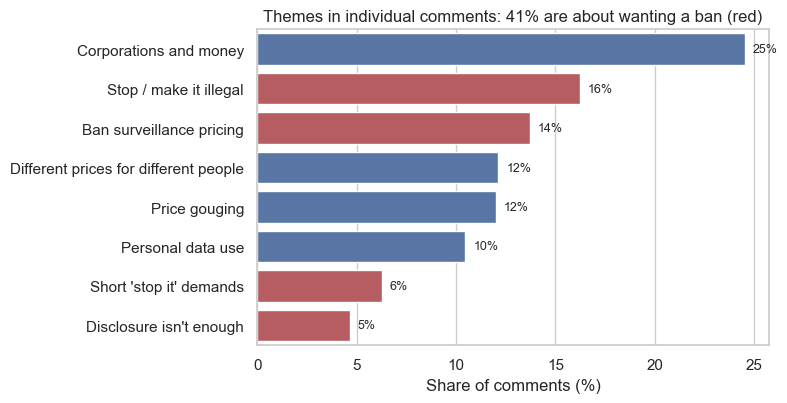

In [24]:
# Names make the topics readable in the report and slides. The
# mapping lets us later test topic modelling as a simple baseline
# classifier against the human gold standard.


# 1. Plain-English names (based on each topic's top words) ---
TOPIC_NAMES = {
    0: "Personal data use",
    1: "Ban surveillance pricing",
    2: "Stop / make it illegal",
    3: "Price gouging",
    4: "Short 'stop it' demands",
    5: "Disclosure isn't enough",
    6: "Corporations and money",
    7: "Different prices for different people",
}

# 2. Map each topic to the codebook concern it matches best ---
# Topics about *wanting a ban* say what people want, not why, so they
# map to "other": this is a known weakness of topics as a classifier.
TOPIC_TO_CONCERN = {
    0: "privacy_data_use",
    1: "other",
    2: "other",
    3: "corporate_greed_gouging",
    4: "other",
    5: "transparency_disclosure",
    6: "corporate_greed_gouging",
    7: "fairness_discrimination",
}
df["topic_name"] = df["topic"].map(TOPIC_NAMES)
df["topic_concern"] = df["topic"].map(TOPIC_TO_CONCERN)   # baseline prediction, scored in Section 8

# 3. Chart: share of comments per topic
# Largest theme on top; the four topics about wanting a ban are highlighted,
# because together they show how many commenters ask the FTC to go further.
BAN_TOPICS = {"Ban surveillance pricing", "Stop / make it illegal",
              "Short 'stop it' demands", "Disclosure isn't enough"}
topic_share = df["topic_name"].value_counts(normalize=True).sort_values(ascending=False) * 100
colors = ["#C44E52" if name in BAN_TOPICS else "#4C72B0" for name in topic_share.index]

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(x=topic_share.values, y=topic_share.index, palette=colors, hue=topic_share.index,
            legend=False, ax=ax)
for i, v in enumerate(topic_share.values):
    ax.text(v + 0.4, i, f"{v:.0f}%", va="center", fontsize=9)
ban_total = topic_share[topic_share.index.isin(BAN_TOPICS)].sum()
ax.set(title=f"Themes in individual comments: {ban_total:.0f}% are about wanting a ban (red)",
       xlabel="Share of comments (%)", ylabel="")
plt.tight_layout()
plt.savefig(FIG / "topics.png", dpi=150, bbox_inches="tight")
plt.show()

Together, the four ban-related topics cover **41% of comments**, an early sign that many commenters want the FTC to go further than disclosure. Because topics group words rather than meaning, this is an estimate; the validated figure comes from the LLM's `requested_action` labels.